In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
import numpy as np, sympy as sp
from IPython.display import Image, display, Markdown
sp.init_printing(use_unicode=True)
def show(path):
    p = path[0] if isinstance(path, tuple) else path
    display(Image(filename=p))


# 08. Horizon crossing

The crossover $x=1$ is where subhorizon and superhorizon approximations both fail. Check the exact amplitude there ($\sqrt2$ in units of $H/(M_{pl}k^{3/2})$),
confirm there is no error spike, and use residual diagnostics that do not rely on knowing the exact solution.

In [2]:
from desitter_perturbations.spectra import mode_spectrum as msp
print("|gamma| at x = 1 in reference units:", msp.horizon_crossing_amplitude(), "  exact sqrt(2) =", np.sqrt(2))

|gamma| at x = 1 in reference units: 1.4142135625098884   exact sqrt(2) = 1.4142135623730951


In [3]:
from desitter_perturbations.dynamics import convergence as cv
traj = cv.error_trajectories(rtols=(1e-4, 1e-7, 1e-10))
for rtol, (x, e) in traj.items():
    near = e[(x > 0.3) & (x < 3)].max(); late = e[x < 0.05].max()
    print(f"rtol {rtol:.0e}: max error near x=1 {near:.2e}, late-time plateau {late:.2e}")

rtol 1e-04: max error near x=1 8.48e-04, late-time plateau 7.12e-04
rtol 1e-07: max error near x=1 7.82e-07, late-time plateau 7.29e-07
rtol 1e-10: max error near x=1 7.33e-10, late-time plateau 6.90e-10


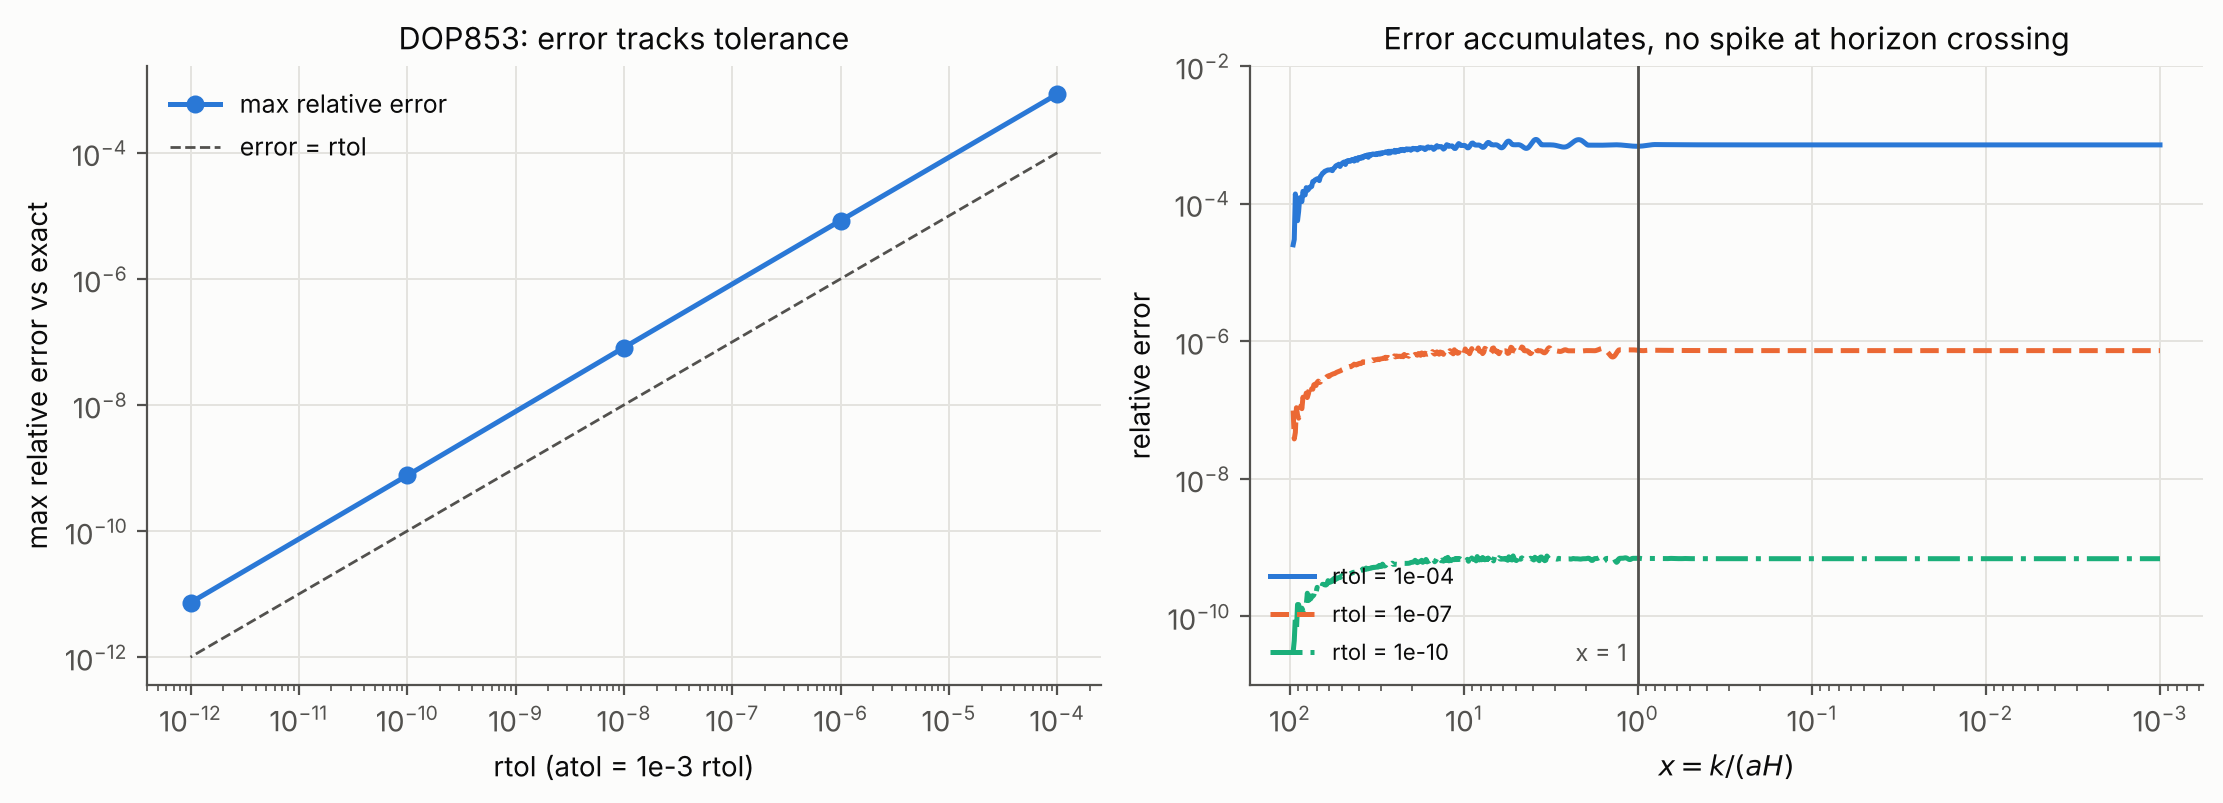

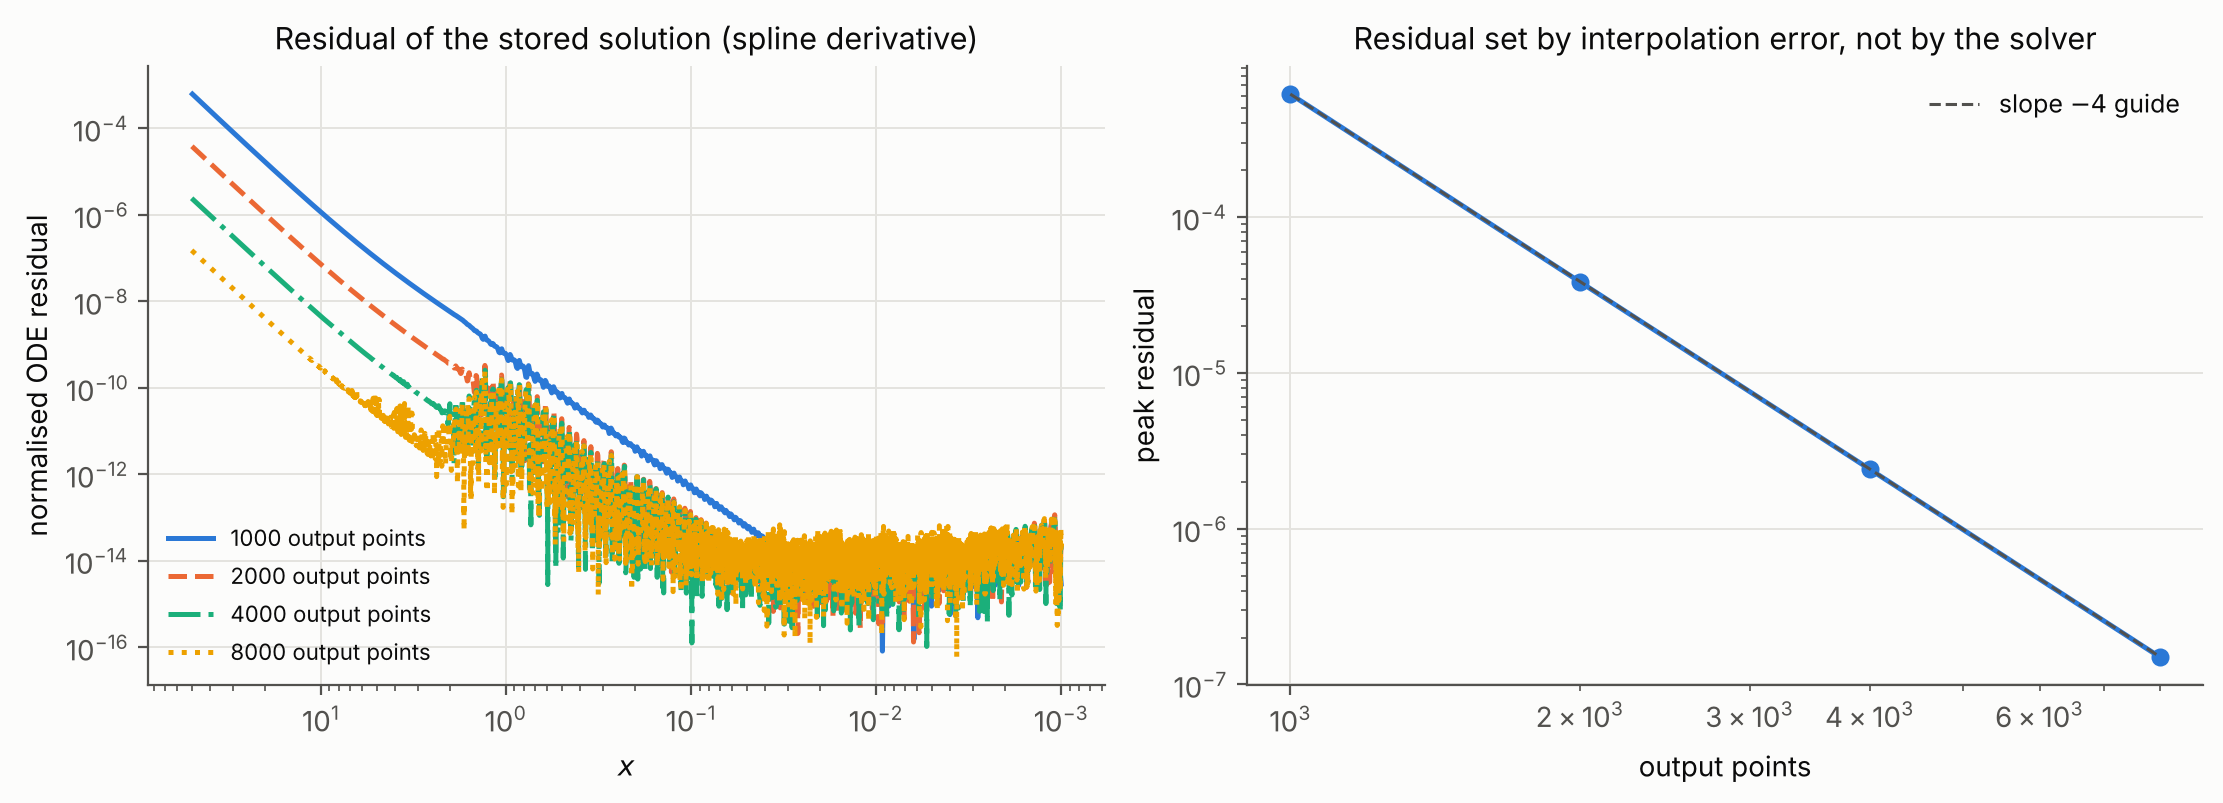

In [4]:
from desitter_perturbations.visualization import mode_plots as mp, convergence_plots as cp
show(cp.plot_tolerance_and_trajectory()); show(mp.plot_residual_diagnostics())

The residual diagnostic is limited by interpolation of the stored output (it converges as the 4th power of output density), not by the integrator.